# 03 · MobileNetV3-Small e EfficientNet-Lite0

**Ementa 03** · O edital prevê duas arquiteturas "de borda": **MobileNetV3-Small** (Howard et al., 2019) e **EfficientNet-Lite0** (variante
para dispositivos do EfficientNet de Tan & Le, 2019). Ambas cabem num Raspberry Pi e respondem em dezenas de milissegundos — por causa de
uma ideia central, a **convolução separável em profundidade**.

Neste notebook você vai: **(1)** calcular por que a convolução separável é ~8× mais barata; **(2)** dissecar um bloco de cada arquitetura
(MBConv, *squeeze-and-excitation*, *hard-swish*); **(3)** comparar parâmetros, operações e latência; **(4)** treinar os **três modelos de triagem**
(RD, glaucoma, DMRI) com as **duas** arquiteturas; **(5)** comparar acurácia × custo — a escolha final, com o modelo já quantizado, fica para o notebook 04.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import json, time
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from keras import layers

from retina_iae import conversao as C, dados as D, inferencia as I, metricas as Me, modelos as M, treino as T, visualizacao as V

V.configurar_estilo()
cache = D.Cache()
ARQS = ["mobilenetv3_small", "efficientnet_lite0"]

## 1. Convolução padrão × convolução separável

Uma convolução padrão k×k com C_e canais de entrada e C_s de saída, num mapa H×W, faz **H·W·k²·C_e·C_s** multiplicações: cada filtro
mistura, ao mesmo tempo, o **espaço** (k×k) e os **canais** (C_e). A versão separável faz as duas coisas em sequência:

1. **depthwise** k×k: um filtro por canal, sem misturar canais → H·W·k²·C_e;
2. **pointwise** 1×1: mistura os canais, sem olhar a vizinhança → H·W·C_e·C_s.

Razão de custo: (k²·C_e + C_e·C_s) / (k²·C_e·C_s) = 1/C_s + 1/k² ≈ **1/9** para k = 3.

In [2]:
H = W = 28; Ce = Cs = 96; k = 3
padrao = H * W * k * k * Ce * Cs
separavel = H * W * k * k * Ce + H * W * Ce * Cs
print(f"padrão   : {padrao / 1e6:6.1f} M MACs | {k * k * Ce * Cs:,} parâmetros".replace(",", "."))
print(f"separável: {separavel / 1e6:6.1f} M MACs | {k * k * Ce + Ce * Cs:,} parâmetros  →  {padrao / separavel:.1f}× mais barata".replace(",", "."))

def cronometrar(camadas, n=20):
    m = keras.Sequential([keras.Input((H, W, Ce))] + camadas)
    x = np.random.rand(16, H, W, Ce).astype(np.float32); m(x)
    t0 = time.perf_counter()
    for _ in range(n): m(x)
    return (time.perf_counter() - t0) / n * 1e3

print(f"\ntempo no PC (lote 16): padrão {cronometrar([layers.Conv2D(Cs, k, padding='same')]):.1f} ms · "
      f"separável {cronometrar([layers.DepthwiseConv2D(k, padding='same'), layers.Conv2D(Cs, 1)]):.1f} ms")

padrão   :   65.0 M MACs | 82.944 parâmetros
separável:    7.9 M MACs | 10.080 parâmetros  →  8.2× mais barata



tempo no PC (lote 16): padrão 5.5 ms · separável 3.5 ms


O ganho em tempo real é menor que o ganho em operações (a depthwise faz pouca conta por byte lido da memória), mas continua grande — e em
processadores pequenos, como o ARM do Pi, memória e operações pesam juntos.

## 2. Os blocos de cada arquitetura

Ambas usam o **bloco residual invertido (MBConv)** do MobileNetV2: **expande** os canais com 1×1 (×6), aplica a **depthwise** k×k nesse espaço
largo, **projeta** de volta com 1×1 *sem ativação* (gargalo linear) e soma a entrada (atalho residual) quando as formas coincidem.

| | MobileNetV3-Small | EfficientNet-Lite0 |
|---|---|---|
| bloco | MBConv **+ squeeze-and-excitation (SE)** em parte dos blocos | MBConv, **sem SE** |
| ativação | ReLU e **hard-swish** (x·ReLU6(x+3)/6) | **ReLU6** em toda a rede |
| como foi desenhada | busca automática de arquitetura (NAS) mirando latência em celular | EfficientNet-B0 "simplificada" para aceleradores e quantização |
| entrada no pré-treino | [−1, 1] (camada embutida no Keras) | [−1, 1] |

O **SE** calcula, para cada canal, um peso entre 0 e 1 a partir da média global do mapa ("quanto este canal importa nesta imagem") e
multiplica o canal por ele. Ajuda a acurácia, mas cria multiplicações elemento a elemento e médias globais no meio da rede — operações
que **quantizam mal** e que alguns aceleradores não suportam. A versão *Lite* removeu o SE e trocou *swish* por ReLU6 exatamente por isso
(veremos o efeito, medido, no notebook 04).

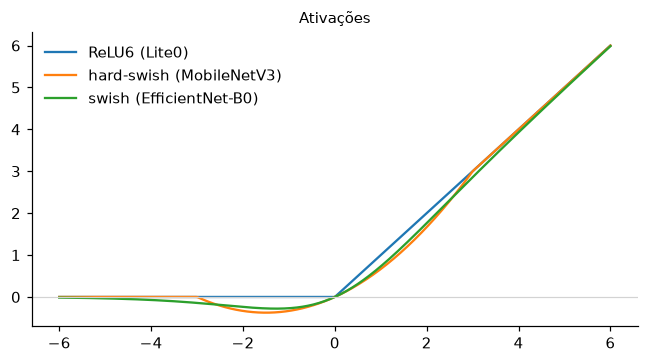

In [3]:
x_ = np.linspace(-6, 6, 400)
relu6 = np.clip(x_, 0, 6); hswish = x_ * np.clip(x_ + 3, 0, 6) / 6; swish = x_ / (1 + np.exp(-x_))
fig, ax = plt.subplots(figsize=(6, 3.4))
for y_, n in [(relu6, "ReLU6 (Lite0)"), (hswish, "hard-swish (MobileNetV3)"), (swish, "swish (EfficientNet-B0)")]:
    ax.plot(x_, y_, label=n)
ax.legend(frameon=False); ax.set_title("Ativações"); ax.axhline(0, color="lightgray", lw=0.8)
fig.tight_layout(); plt.show()

In [4]:
def camadas_do_bloco(base, prefixo):
    return [{"camada": c.name.replace(prefixo, "…"), "tipo": type(c).__name__, "saída": str(c.output.shape[1:])}
            for c in base.layers if c.name.startswith(prefixo)]

base_mn = M.criar_base("mobilenetv3_small"); base_lite = M.criar_base("efficientnet_lite0")
print("MobileNetV3-Small — bloco 'expanded_conv_3' (com SE e hard-swish):")
display(pd.DataFrame(camadas_do_bloco(base_mn, "expanded_conv_3_")).set_index("camada"))
print("EfficientNet-Lite0 — bloco 'blocks_2_1' (sem SE, ReLU6, com atalho):")
display(pd.DataFrame(camadas_do_bloco(base_lite, "blocks_2_1_")).set_index("camada"))

MobileNetV3-Small — bloco 'expanded_conv_3' (com SE e hard-swish):


,tipo,saída
camada,,
…expand,Conv2D,"(28, 28, 96)"
…expand_bn,BatchNormalization,"(28, 28, 96)"
…depthwise_pad,ZeroPadding2D,"(31, 31, 96)"
…depthwise,DepthwiseConv2D,"(14, 14, 96)"
…depthwise_bn,BatchNormalization,"(14, 14, 96)"
…squeeze_excite_avg_pool,GlobalAveragePooling2D,"(1, 1, 96)"
…squeeze_excite_conv,Conv2D,"(1, 1, 24)"
…squeeze_excite_relu,ReLU,"(1, 1, 24)"
…squeeze_excite_conv_1,Conv2D,"(1, 1, 96)"


EfficientNet-Lite0 — bloco 'blocks_2_1' (sem SE, ReLU6, com atalho):


,tipo,saída
camada,,
…conv_pw,Conv2D,"(28, 28, 240)"
…bn1,BatchNormalization,"(28, 28, 240)"
…bn1_relu6,ReLU,"(28, 28, 240)"
…conv_dw,DepthwiseConv2D,"(28, 28, 240)"
…bn2,BatchNormalization,"(28, 28, 240)"
…bn2_relu6,ReLU,"(28, 28, 240)"
…conv_pwl,Conv2D,"(28, 28, 40)"
…bn3,BatchNormalization,"(28, 28, 40)"
…soma,Add,"(28, 28, 40)"


## 3. Custo de cada arquitetura

Parâmetros, multiplicações-acumulações (MACs) por imagem 224×224 e latência no **LiteRT** deste PC (modelo float32, 4 threads — o mesmo número de núcleos do Pi 5).

In [5]:
linhas = []
for nome in ["cnn_simples", *ARQS]:
    m = M.criar_classificador(nome, 224)
    lat = I.ModeloTFLite(C.converter(m, "float32"), threads=4).medir_latencia(repeticoes=30)
    linhas.append({"modelo": nome, **{k: round(v, 2) for k, v in M.resumo_custo(m).items()}, "latência PC (ms)": round(lat["mediana_ms"], 1)})
custo = pd.DataFrame(linhas).set_index("modelo"); custo

,parametros_M,MACs_M,float32_MB,int8_MB,latência PC (ms)
modelo,,,,,
cnn_simples,0.10,195.08,0.39,0.10,2.2
mobilenetv3_small,0.94,54.90,3.76,0.94,1.5
efficientnet_lite0,3.41,383.91,13.66,3.41,4.8


O Lite0 tem ≈ 3,6× os parâmetros e ≈ 7× as operações do MobileNetV3-Small. A pergunta deste notebook: **esse custo compra acurácia?**
(A CNN do notebook 01 tem poucos parâmetros mas, em 224 px, mais operações que o MobileNetV3 — o custo depende de *onde* estão as contas.)

## 4. Treinando os três modelos com as duas arquiteturas

Para cada tarefa e arquitetura: transfer learning em duas fases (notebook 02), parada antecipada pela AUC de validação, pesos de classe.
Os modelos são salvos em `outputs/keras/<tarefa>_<arquitetura>.keras` e usados nos notebooks 04 e 06.

*(≈ 30–40 min em CPU de 8 núcleos. Com `RETREINAR = False`, modelos já salvos são reaproveitados.)*

In [6]:
RETREINAR = True
historicos, linhas = {}, []
for tarefa in D.TAREFAS:
    tr = D.conjunto(tarefa, "treino", cache)[:2]
    va = D.conjunto(tarefa, "validacao", cache)[:2]
    for arq in ARQS:
        caminho = T.caminho_keras(tarefa, arq)
        t0 = time.time()
        if RETREINAR or not caminho.exists():
            m = M.criar_classificador(arq, nome=f"{tarefa}_{arq}")
            h = T.treinar_duas_fases(m, tr, va, epocas_cabeca=4, epocas_ajuste=12, paciencia=4, semente=0)
            T.salvar(m, tarefa, arq)
            h.to_csv(caminho.with_suffix(".historico.csv"), index=False)
        else:
            m = T.carregar(tarefa, arq); h = pd.read_csv(caminho.with_suffix(".historico.csv"))
        historicos[(tarefa, arq)] = h
        p_va = T.prever(m, va[0])
        linhas.append({"tarefa": tarefa, "arquitetura": arq, "imagens treino": len(tr[1]), "positivas": int(tr[1].sum()),
                       "épocas": len(h), "minutos": round((time.time() - t0) / 60, 1), "AUC validação": Me.auc(va[1], p_va)})
        print(f"{tarefa:9s} {arq:18s} {linhas[-1]['épocas']:2d} épocas  {linhas[-1]['minutos']:5.1f} min  AUC val {linhas[-1]['AUC validação']:.3f}")
treinos = pd.DataFrame(linhas)

rd        mobilenetv3_small  16 épocas    3.7 min  AUC val 0.986


rd        efficientnet_lite0 16 épocas   10.6 min  AUC val 0.988


glaucoma  mobilenetv3_small  13 épocas    2.7 min  AUC val 0.912


glaucoma  efficientnet_lite0 12 épocas    6.5 min  AUC val 0.918


dmri      mobilenetv3_small  12 épocas    2.3 min  AUC val 0.889


dmri      efficientnet_lite0 16 épocas    8.9 min  AUC val 0.926


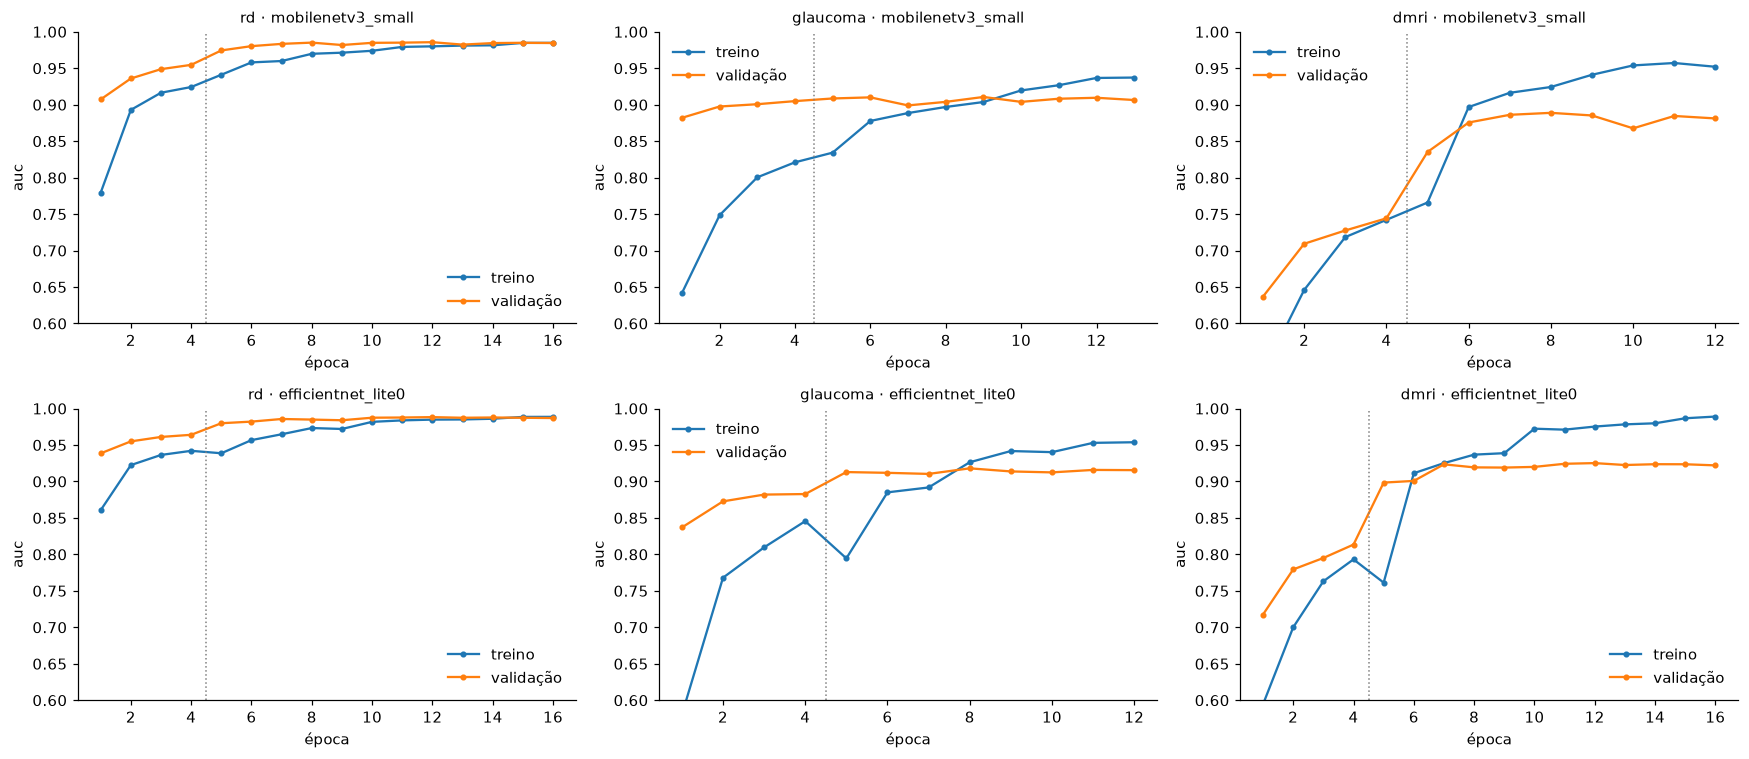

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(16, 7))
for j, tarefa in enumerate(D.TAREFAS):
    for i, arq in enumerate(ARQS):
        V.historico(historicos[(tarefa, arq)], axs[i, j], "auc", f"{tarefa} · {arq}")
        axs[i, j].set_ylim(0.6, 1.0)
fig.tight_layout(); V.salvar_figura(fig, "03_historicos"); plt.show()

Três coisas para notar:

* O **ajuste fino** (depois da linha pontilhada) dá o maior salto na DMRI; no glaucoma e na RD a cabeça sozinha já chega perto do resultado final.
* Na RD (2,5 mil imagens) treino e validação terminam juntos. No **glaucoma e na DMRI** (≈ 200 positivos no treino) aparece o que **não** vimos
  com a CNN pequena do notebook 01: a AUC de treino continua subindo enquanto a de validação estaciona — o começo do **sobreajuste**, agora com
  1–3 milhões de parâmetros e poucos exemplos. A parada antecipada guarda a melhor época de validação.
* Com ≈ 40 positivos na validação, cada um pesa ≈ 2,5 pontos de sensibilidade: a validação é ruidosa, e a escolha da "melhor época" também.

## 5. Acurácia × custo

AUC no **teste** (da mesma fonte; validação externa só no notebook 06), com IC 95 % por bootstrap:

In [8]:
linhas = []
for tarefa in D.TAREFAS:
    Xte, yte, tte = D.conjunto(tarefa, "teste", cache)
    for arq in ARQS:
        p = T.prever(T.carregar(tarefa, arq), Xte)
        a, lo, hi = Me.bootstrap(yte, p, Me.auc, n=1000, grupos=tte.paciente.where(tte.paciente != "", tte.id).to_numpy())
        linhas.append({"tarefa": tarefa, "arquitetura": arq, "AUC teste": a, "IC 95 %": f"{lo:.3f}–{hi:.3f}",
                       "MACs (M)": custo.loc[arq, "MACs_M"], "latência PC (ms)": custo.loc[arq, "latência PC (ms)"]})
comparacao = pd.DataFrame(linhas).merge(treinos[["tarefa", "arquitetura", "AUC validação", "minutos"]], on=["tarefa", "arquitetura"])
comparacao.set_index(["tarefa", "arquitetura"]).round(3)

AUC teste      IC 95 %  MACs (M)  \
tarefa   arquitetura                                            
rd       mobilenetv3_small       0.980  0.969–0.988     54.90   
         efficientnet_lite0      0.985  0.977–0.992    383.91   
glaucoma mobilenetv3_small       0.878  0.801–0.936     54.90   
         efficientnet_lite0      0.912  0.862–0.954    383.91   
dmri     mobilenetv3_small       0.912  0.858–0.962     54.90   
         efficientnet_lite0      0.899  0.830–0.956    383.91   

                             latência PC (ms)  AUC validação  minutos  
tarefa   arquitetura                                                   
rd       mobilenetv3_small                1.5          0.986      3.7  
         efficientnet_lite0               4.8          0.988     10.6  
glaucoma mobilenetv3_small                1.5          0.912      2.7  
         efficientnet_lite0               4.8          0.918      6.5  
dmri     mobilenetv3_small                1.5          0.889      2.3  
         efficientnet_lite0               4.8          0.926      8.9

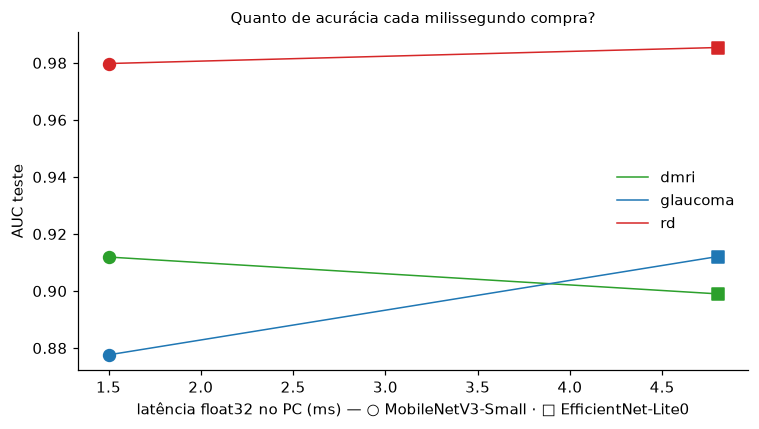

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
cores = {"rd": "tab:red", "glaucoma": "tab:blue", "dmri": "tab:green"}
for _, r in comparacao.iterrows():
    ax.scatter(r["latência PC (ms)"], r["AUC teste"], color=cores[r.tarefa], marker="o" if "mobile" in r.arquitetura else "s", s=60)
for tarefa, g in comparacao.groupby("tarefa"):
    ax.plot(g["latência PC (ms)"], g["AUC teste"], color=cores[tarefa], lw=1, label=tarefa)
ax.set_xlabel("latência float32 no PC (ms) — ○ MobileNetV3-Small · □ EfficientNet-Lite0"); ax.set_ylabel("AUC teste")
ax.legend(frameon=False); ax.set_title("Quanto de acurácia cada milissegundo compra?")
fig.tight_layout(); V.salvar_figura(fig, "03_acuracia_custo"); plt.show()

(D.SAIDAS / "comparacao_arquiteturas.csv").parent.mkdir(parents=True, exist_ok=True)
comparacao.to_csv(D.SAIDAS / "comparacao_arquiteturas.csv", index=False)

Como ler (os números exatos estão na tabela acima):

* As diferenças de AUC entre as arquiteturas, no teste interno, ficam em geral **dentro dos intervalos de confiança** — com estes tamanhos de
  amostra, não dá para afirmar que uma é melhor que a outra *nesta* fonte.
* O custo, ao contrário, é **muito** diferente (≈ 7× em operações). Para um dispositivo de borda, o desempate natural é o modelo mais leve —
  **desde que** ele sobreviva à quantização e à câmera nova. Os dois critérios ficam para os notebooks 04 (int8) e 06 (validação externa).
* Todas as latências estão **muito abaixo** da meta de 3 s por condição. O gargalo do dispositivo, como veremos no notebook 05, é o
  pré-processamento do Módulo 02 sobre a captura de 12 MP — não a rede.

## Exercícios propostos

1. **Largura do MobileNetV3.** `keras.applications.MobileNetV3Small(alpha=0.75)` tem pesos ImageNet. Treine a tarefa RD com ele (adapte
   `criar_base`). Quanto se perde de AUC e quanto se ganha de latência?
2. **Variante "minimalista".** `MobileNetV3Small(minimalistic=True)` remove SE e hard-swish (como o Lite). Compare com a versão completa aqui e,
   depois do notebook 04, também em int8.
3. **Sementes.** Retreine o modelo de glaucoma com `semente` = 1, 2 e 3. Quanto a AUC de validação varia só pela aleatoriedade? Compare com a
   diferença entre as arquiteturas.
4. **Resolução.** Treine o modelo de RD com entrada 160 (`criar_classificador(..., entrada=160)` e `tamanho=160` no treino). Que fração da
   latência você economiza e quanto de AUC perde? (Lembre que o APTOS já está em 224 px.)
5. **Um modelo multitarefa?** Em vez de três modelos, uma única base com três saídas sigmoides. Quais seriam as vantagens no Pi (memória,
   tempo)? E as dificuldades com os dados (cada imagem só tem rótulo de uma tarefa)?